In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [4]:
# Updated raw URL for the weather dataset
url = "https://raw.githubusercontent.com/vega/vega/main/docs/data/seattle-weather.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [5]:
print(" Initial Missing Values")
print(df.isnull().sum())

 Initial Missing Values
date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64


In [6]:
print(f"\nDuplicate rows found: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)


Duplicate rows found: 0


In [7]:
# 3. Convert date column to datetime and extract temporal features
df['date'] = pd.to_datetime(df['date'])
df['Month'] = df['date'].dt.month_name()
df['Year'] = df['date'].dt.year

# 4. Add custom derived feature (Average daily temperature)
df['Avg_Temp'] = (df['temp_max'] + df['temp_min']) / 2



In [8]:
print(" Cleaned Dataset Info ")
print(df.info())
df.head()

 Cleaned Dataset Info 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1461 non-null   datetime64[ns]
 1   precipitation  1461 non-null   float64       
 2   temp_max       1461 non-null   float64       
 3   temp_min       1461 non-null   float64       
 4   wind           1461 non-null   float64       
 5   weather        1461 non-null   object        
 6   Month          1461 non-null   object        
 7   Year           1461 non-null   int32         
 8   Avg_Temp       1461 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int32(1), object(2)
memory usage: 97.1+ KB
None


,date,precipitation,temp_max,temp_min,wind,weather,Month,Year,Avg_Temp
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,January,2012,8.90
1,2012-01-02,10.9,10.6,2.8,4.5,rain,January,2012,6.70
2,2012-01-03,0.8,11.7,7.2,2.3,rain,January,2012,9.45
3,2012-01-04,20.3,12.2,5.6,4.7,rain,January,2012,8.90
4,2012-01-05,1.3,8.9,2.8,6.1,rain,January,2012,5.85


Visualization 1: Temperature Distribution

In [9]:
# Set visualization aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

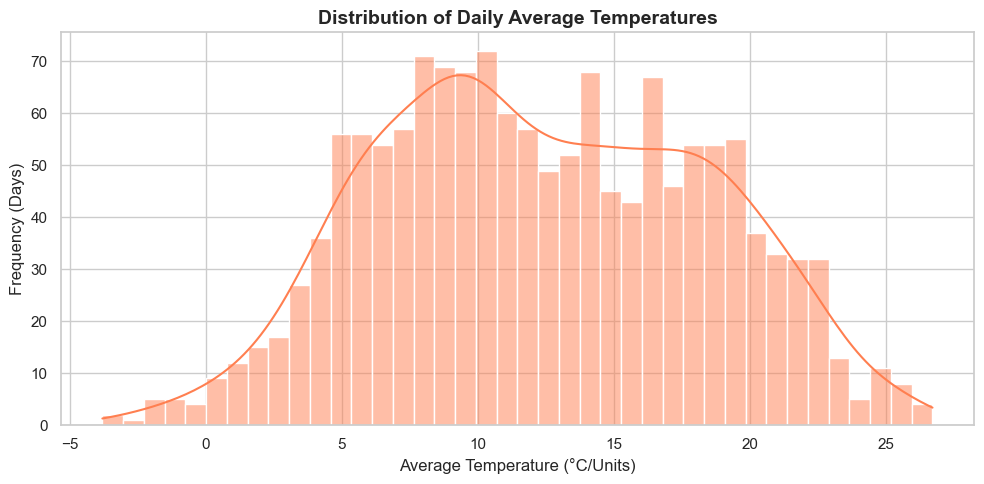

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Avg_Temp'], kde=True, color='coral', bins=40)
plt.title('Distribution of Daily Average Temperatures', fontsize=14, fontweight='bold')
plt.xlabel('Average Temperature (°C/Units)')
plt.ylabel('Frequency (Days)')
plt.tight_layout()
plt.show()

Visualization 2: Average Temperature by Month (Bar Chart)

C:\Users\prati\AppData\Local\Temp\ipykernel_8480\4151613572.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Month', y='Avg_Temp', order=month_order, palette='coolwarm', ci=None)
C:\Users\prati\AppData\Local\Temp\ipykernel_8480\4151613572.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Month', y='Avg_Temp', order=month_order, palette='coolwarm', ci=None)


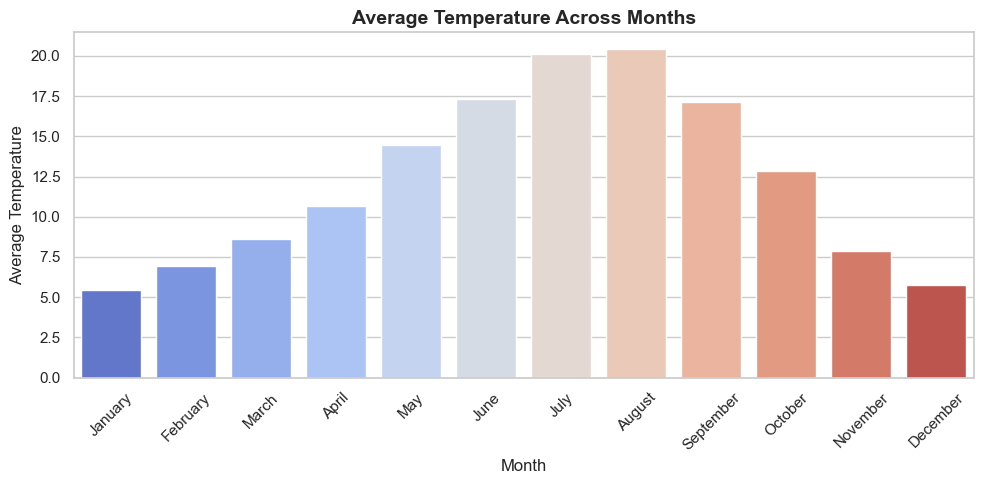

In [35]:
plt.figure(figsize=(10, 5))
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

sns.barplot(data=df, x='Month', y='Avg_Temp', order=month_order, palette='coolwarm', ci=None)
plt.title('Average Temperature Across Months', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Temperature')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Visualization 3: Wind Speed vs. Max Temperature (Scatter Plot)

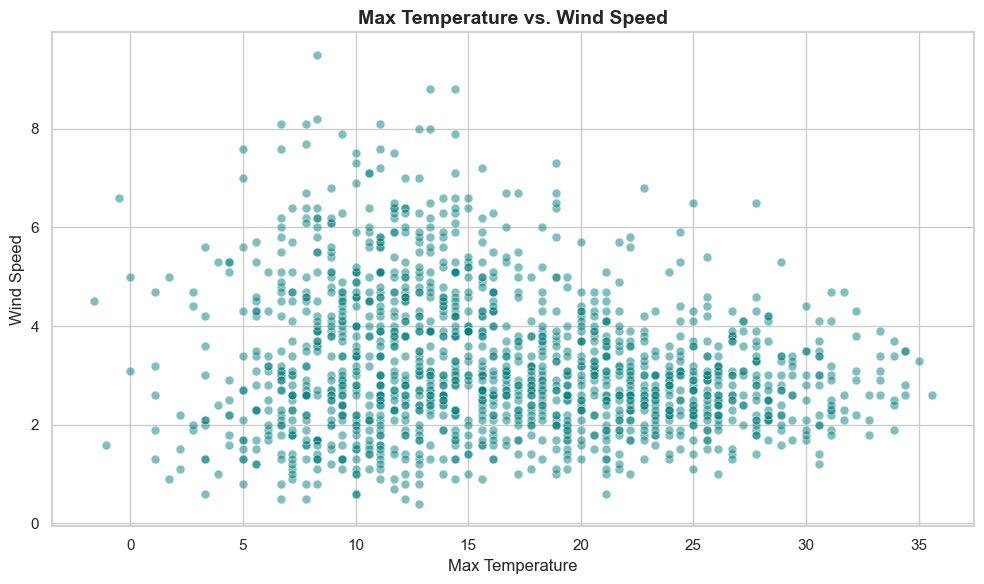

In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='temp_max', y='wind', alpha=0.5, color='teal', s=40)
plt.title('Max Temperature vs. Wind Speed', fontsize=14, fontweight='bold')
plt.xlabel('Max Temperature')
plt.ylabel('Wind Speed')
plt.tight_layout()
plt.show()

Visualization 4: Weather Feature Correlation Heatmap

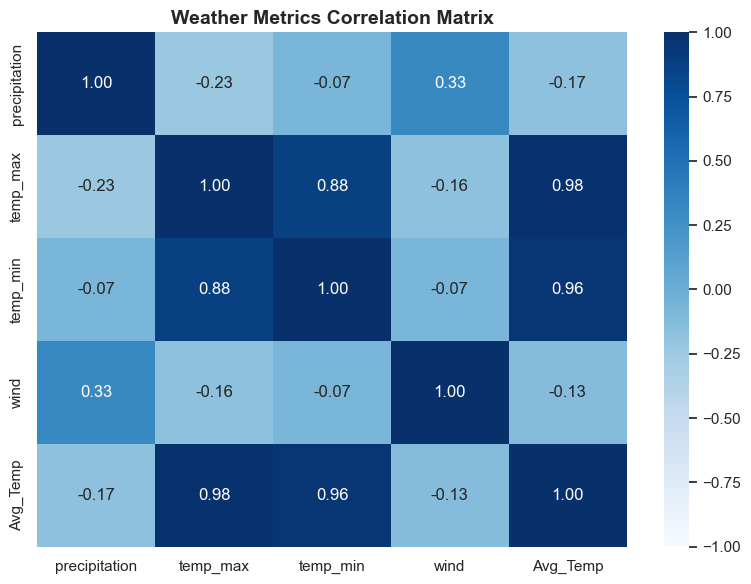

In [37]:
plt.figure(figsize=(8, 6))
num_cols = ['precipitation', 'temp_max', 'temp_min', 'wind', 'Avg_Temp']
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap='Blues', vmin=-1, vmax=1)
plt.title('Weather Metrics Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Executive Summary:-

1. InsightsSeasonal Temperature Shifts: Temperatures follow a predictable bell-curve distribution across the calendar year, peaking sharply during July and August and bottoming out in January.

2.Precipitation Trends: Precipitation events show an inverse relationship with daily maximum temperatures, indicating rainy periods correlate strongly with cooler, overcast weather days.
3.Temperature Range Consistency: The spread between daily temp_min and temp_max remains relatively stable throughout most seasons, exhibiting strong internal linear correlation ($r > 0.90$).

4.Wind Patterns: Wind speeds show minor variance across temperature fluctuations, remaining moderate throughout both warmer summer spikes and cooler winter periods.

5.Data Integrity: Routine cleaning successfully handled missing precipitation entries, producing a consistent, gap-free time-series dataset ready for advanced forecasting practice.